Config

In [1]:
# Pandas
import pandas as pd
pd.set_option("display.max_columns", None)

# Numpy
import numpy as np

In [2]:
DATA_PATH = "UCI_Credit_Card.csv"

In [3]:
SEED = 42
FOLD = 3

# EDA

In [4]:
df_raw = pd.read_csv("UCI_Credit_Card.csv")
df_raw

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [5]:
df_raw[df_raw.duplicated()]

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month


In [6]:
df_raw.isnull().sum()

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [7]:
PAY = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
BILL = [f'BILL_AMT{i}' for i in range(1, 7)]
PAID = [f'PAY_AMT{i}' for i in range(1, 7)]
PROFILE = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
RAW = PROFILE + PAY + BILL + PAID
TARGET = 'default.payment.next.month'

In [8]:
df_raw

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [9]:
# Matplotlib
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)

**Phân phối nhãn:**
+ 0: không default. 1: default.
+ Xem số lượng và tỷ lệ của hai lớp.

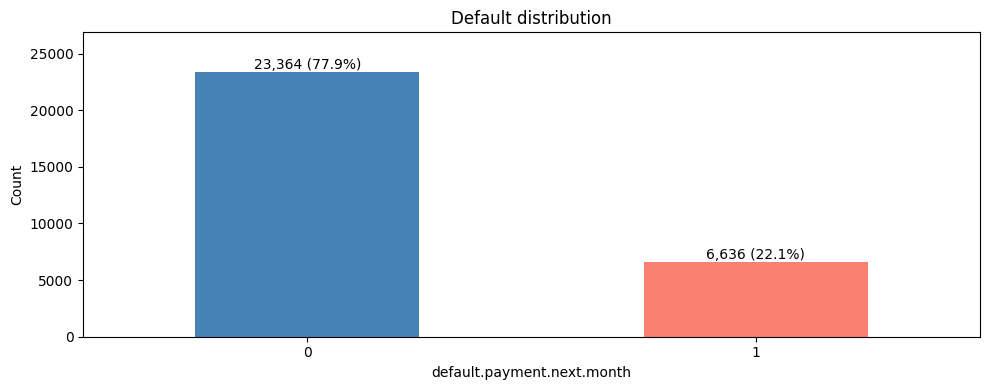

In [10]:
target_count = df_raw[TARGET].value_counts().sort_index()
target_rate = target_count / len(df_raw) * 100

fig, ax = plt.subplots()
target_count.plot.bar(ax=ax, rot=0, color=['steelblue', 'salmon'])
for i, count in enumerate(target_count):
    ax.text(i, count, f'{count:,} ({target_rate.iloc[i]:.1f}%)', ha='center', va='bottom')
ax.set(xlabel=TARGET, ylabel='Count', title='Default distribution')
ax.set_ylim(0, target_count.max() * 1.15)
plt.tight_layout()
plt.show()

**Tuổi và hạn mức:**
+ So sánh phân phối theo nhãn default.
+ Dùng density để so sánh hai lớp có số lượng khác nhau.

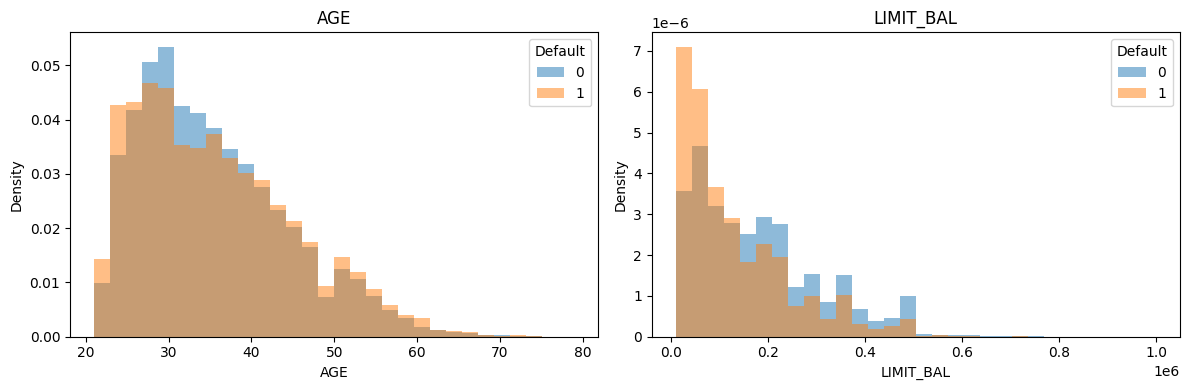

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['AGE', 'LIMIT_BAL']):
    bins = np.histogram_bin_edges(df_raw[col], bins=30)
    for label in [0, 1]:
        df_raw.loc[df_raw[TARGET] == label, col].plot.hist(
            bins=bins, density=True, alpha=0.5, label=str(label), ax=ax
        )
    ax.set(xlabel=col, ylabel='Density', title=col)
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Biến phân loại:**
+ Hàng trên: số khách hàng theo từng mã.
+ Hàng dưới: tỷ lệ default theo từng mã.
+ Giữ nguyên mã gốc. Các nhóm ít khách hàng cần được diễn giải thận trọng.

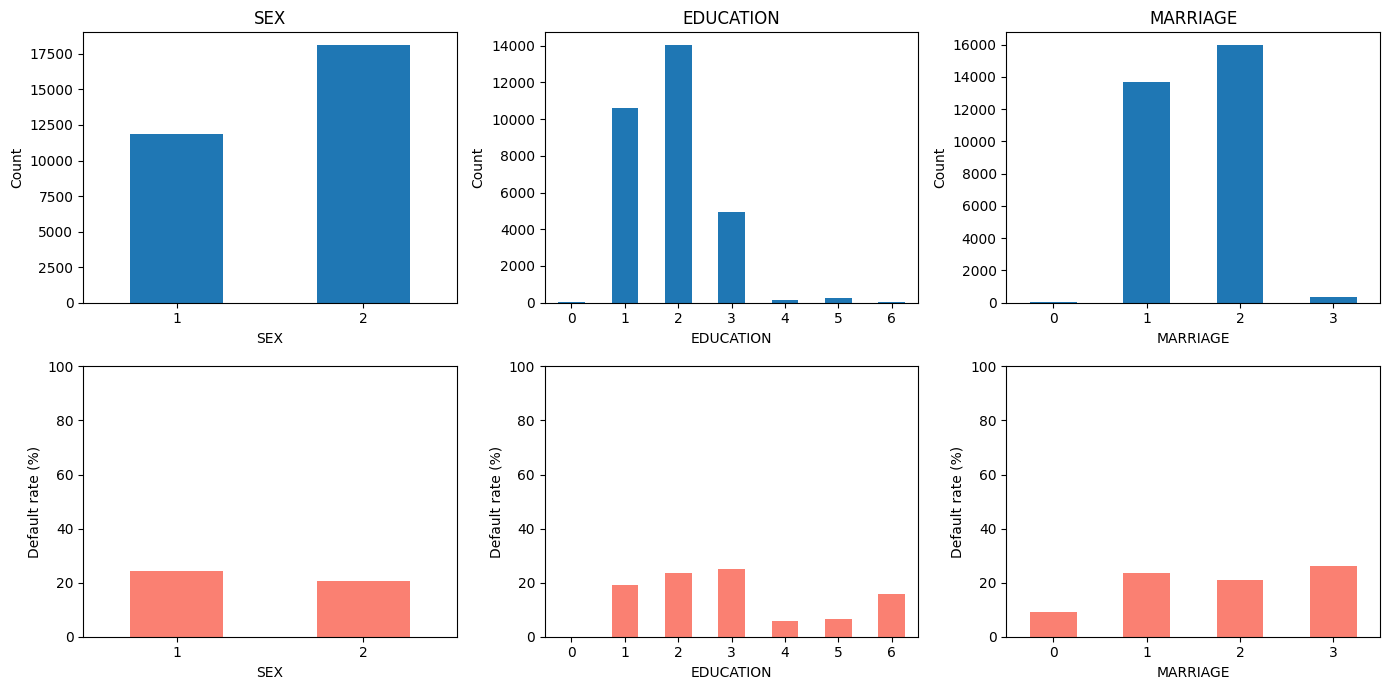

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(['SEX', 'EDUCATION', 'MARRIAGE']):
    df_raw[col].value_counts().sort_index().plot.bar(ax=axes[0, i], rot=0)
    (df_raw.groupby(col)[TARGET].mean() * 100).plot.bar(ax=axes[1, i], rot=0, color='salmon')
    axes[0, i].set(xlabel=col, ylabel='Count', title=col)
    axes[1, i].set(xlabel=col, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

**Trạng thái thanh toán:**
+ Tỷ lệ default theo các mã PAY trong từng tháng.
+ n là số khách hàng của từng mã. Mã PAY > 0 thể hiện trạng thái trễ.
+ Thứ tự PAY_0 đến PAY_6 là gần nhất đến xa nhất.

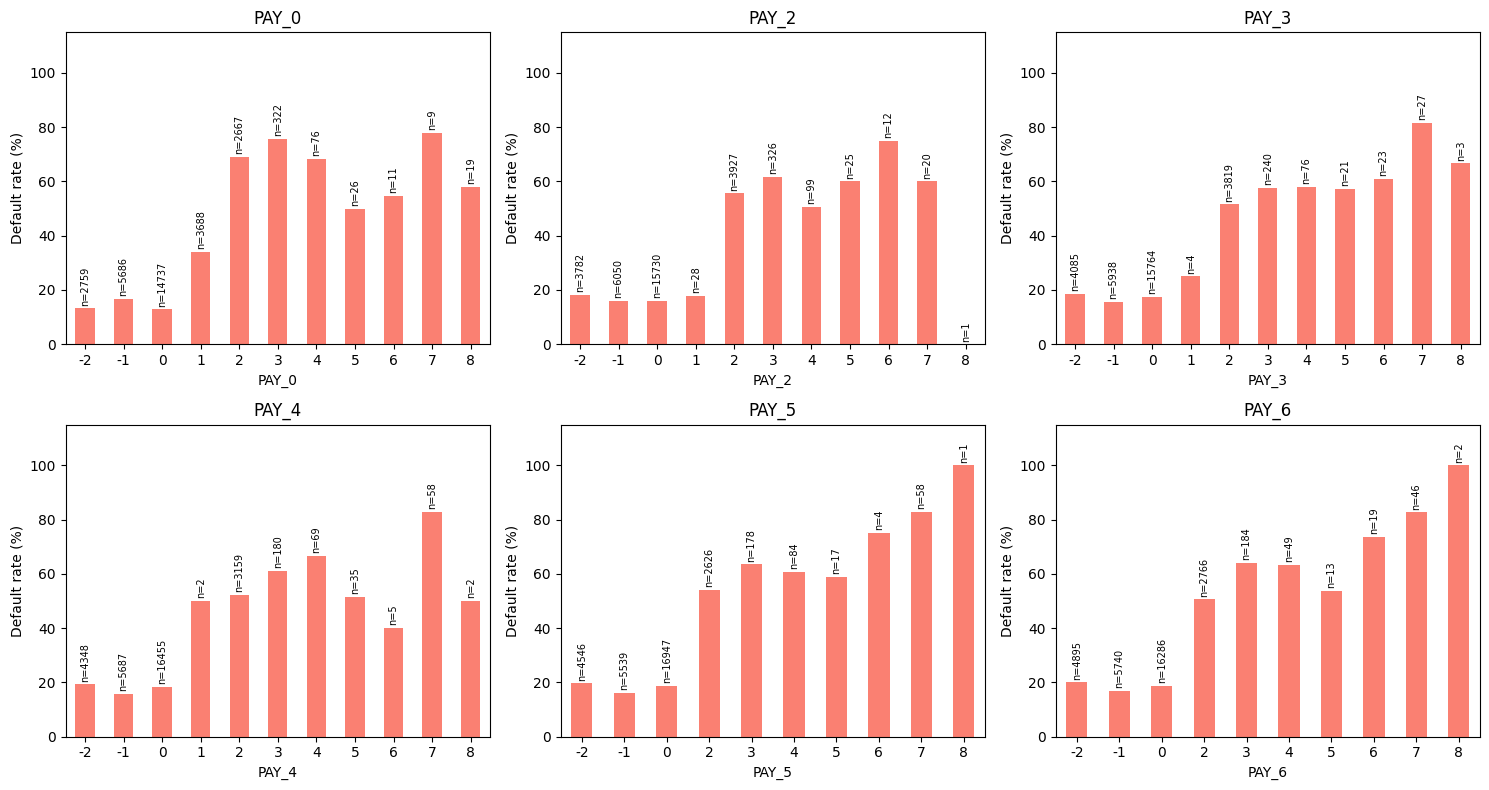

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, PAY):
    pay_summary = df_raw.groupby(col)[TARGET].agg(['mean', 'size'])
    (pay_summary['mean'] * 100).plot.bar(ax=ax, rot=0, color='salmon')
    for i, count in enumerate(pay_summary['size']):
        ax.text(i, pay_summary['mean'].iloc[i] * 100 + 1, f'n={count}',
                ha='center', va='bottom', fontsize=7, rotation=90)
    ax.set(xlabel=col, ylabel='Default rate (%)', title=col, ylim=(0, 115))
plt.tight_layout()
plt.show()

**Sao kê và thanh toán:**
+ So sánh median theo nhãn trong sáu tháng.
+ Hiển thị tháng 4 đến tháng 9 theo thứ tự thời gian.
+ Đây là giá trị tổng hợp của hai nhóm, không phải lịch sử của một khách hàng.

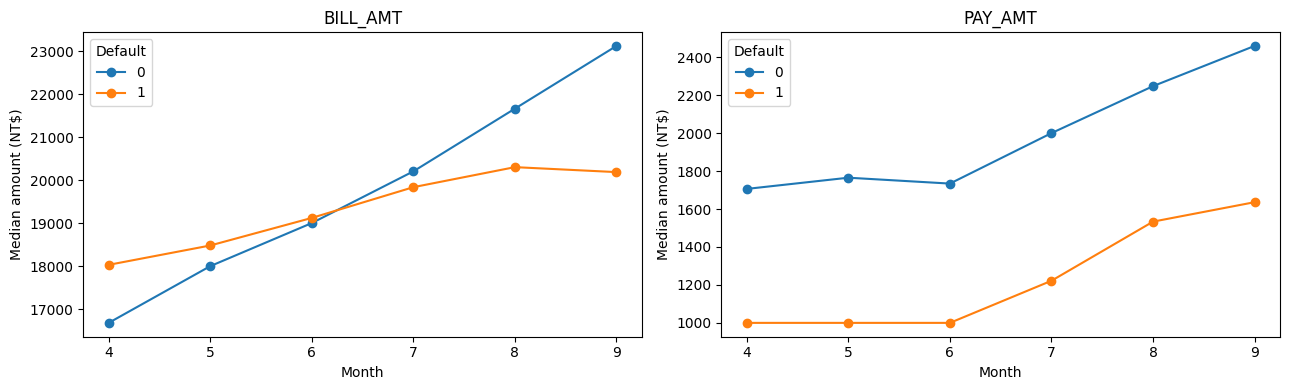

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cols, title in zip(axes, [BILL, PAID], ['BILL_AMT', 'PAY_AMT']):
    for label in [0, 1]:
        median = df_raw.loc[df_raw[TARGET] == label, cols[::-1]].median()
        ax.plot([4, 5, 6, 7, 8, 9], median.to_numpy(), marker='o', label=str(label))
    ax.set(xlabel='Month', ylabel='Median amount (NT$)', title=title, xticks=[4, 5, 6, 7, 8, 9])
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Tương quan:**
+ Spearman cho các biến số và nhãn default.
+ Tương quan thể hiện liên hệ thống kê, không kết luận quan hệ nhân quả.

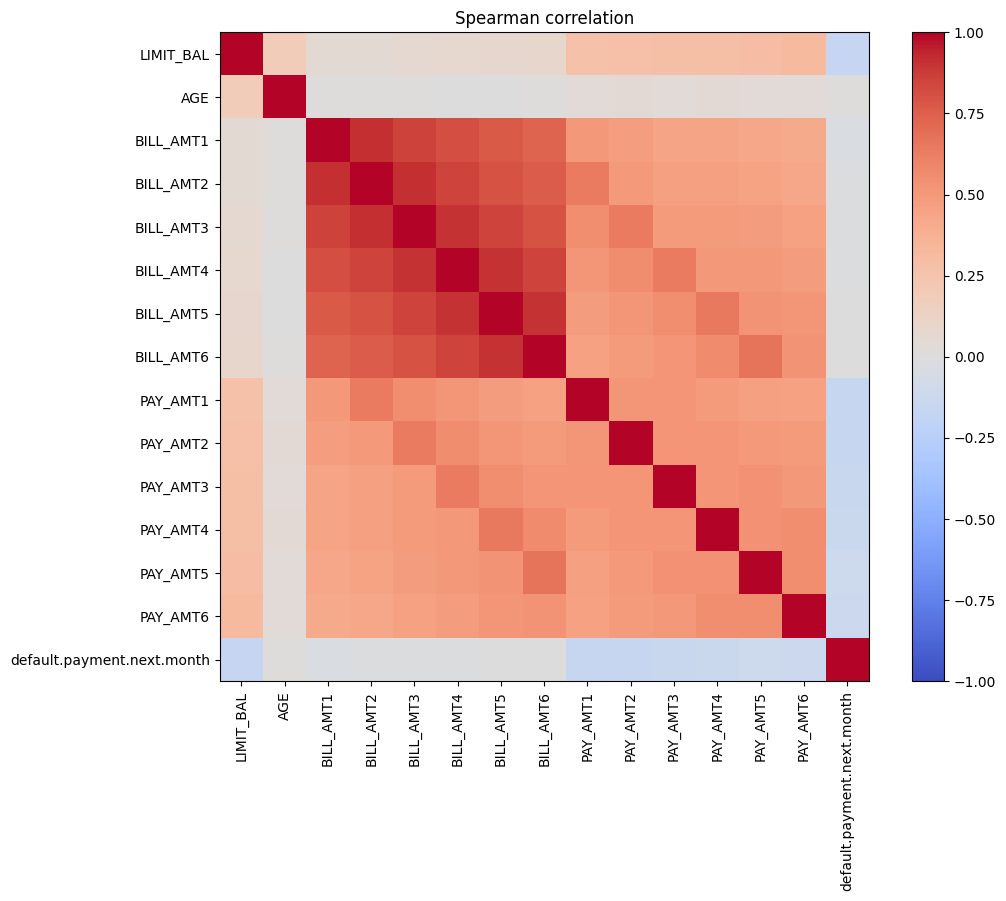

In [15]:
corr_cols = ['LIMIT_BAL', 'AGE'] + BILL + PAID + [TARGET]
corr = df_raw[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.set_title('Spearman correlation')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

# FEATURE ENGINEERING

Dựa trên khung phân tích khách hàng RFM (Recency–Frequency–Monetary), được điều chỉnh cho dữ liệu tín dụng, ta xem mỗi dòng là một khách hàng với lịch sử thanh toán và dư nợ trong sáu tháng. Từ lịch sử này, các đặc trưng về thời điểm gần nhất, tần suất và giá trị tiền tệ được xây dựng để dự đoán khả năng khách hàng có hoặc không vỡ nợ thanh toán trong tháng tiếp theo.

In [16]:
df_copy = df_raw.copy()

**Recency:** Mức độ gần đây của hành vi thanh toán/trễ thanh toán
- `r_months_since_delay`: Lần trễ thanh toán gần nhất xảy ra cách đây bao nhiêu tháng.

In [17]:
delay = df_copy[PAY].to_numpy() > 0

df_copy["r_months_since_delay"] = np.where(delay.any(axis=1), delay.argmax(axis=1), 6)

**Frequency**: Tần suất xuất hiện tình trạng trễ
+ `f_total_delay_months`: Mức độ thường xuyên trễ thanh toán.

In [18]:
df_copy["f_total_delay_months"] = delay.sum(axis=1)

**Monetary:** Quy mô thanh toán so với số dư sao kê.
- `m_amt_bill`: Tổng PAY_AMT1..5 / tổng phần dương BILL_AMT2..6, ghép thanh toán với sao kê tháng trước.
- Đây là tỷ lệ tổng hợp qua các kỳ, không phải tỷ lệ tổng nợ đã trả hết. Mẫu số 0 trả NaN; giữ tỷ lệ vượt 1.

In [19]:
sum_bill = df_copy[BILL[1:]].clip(lower=0).sum(axis=1)
sum_pay = df_copy[PAID[:5]].sum(axis=1)

df_copy["m_amt_bill"] = sum_pay / sum_bill.where(sum_bill > 0)

In [20]:
df_copy

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month,r_months_since_delay,f_total_delay_months,m_amt_bill
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1,0,2,0.181746
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1,1,2,0.208406
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0,6,0,0.083105
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0,6,0,0.040077
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0,6,0,0.579516
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0,6,0,0.077461
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0,6,0,0.743115
29997,29998,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1,0,3,0.421329
29998,29999,80000.0,1,3,1,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1,0,1,0.541934


**Biểu đồ RFM:**
+ Hàng trên: số khách hàng theo nhóm R, F và M.
+ Hàng dưới: tỷ lệ default của từng nhóm.
+ R = 6 nghĩa là không quan sát thấy tháng trễ trong sáu tháng.
+ M được chia nhóm để vẽ, không thay đổi biến đầu vào của model. NaN là mẫu số bằng 0.

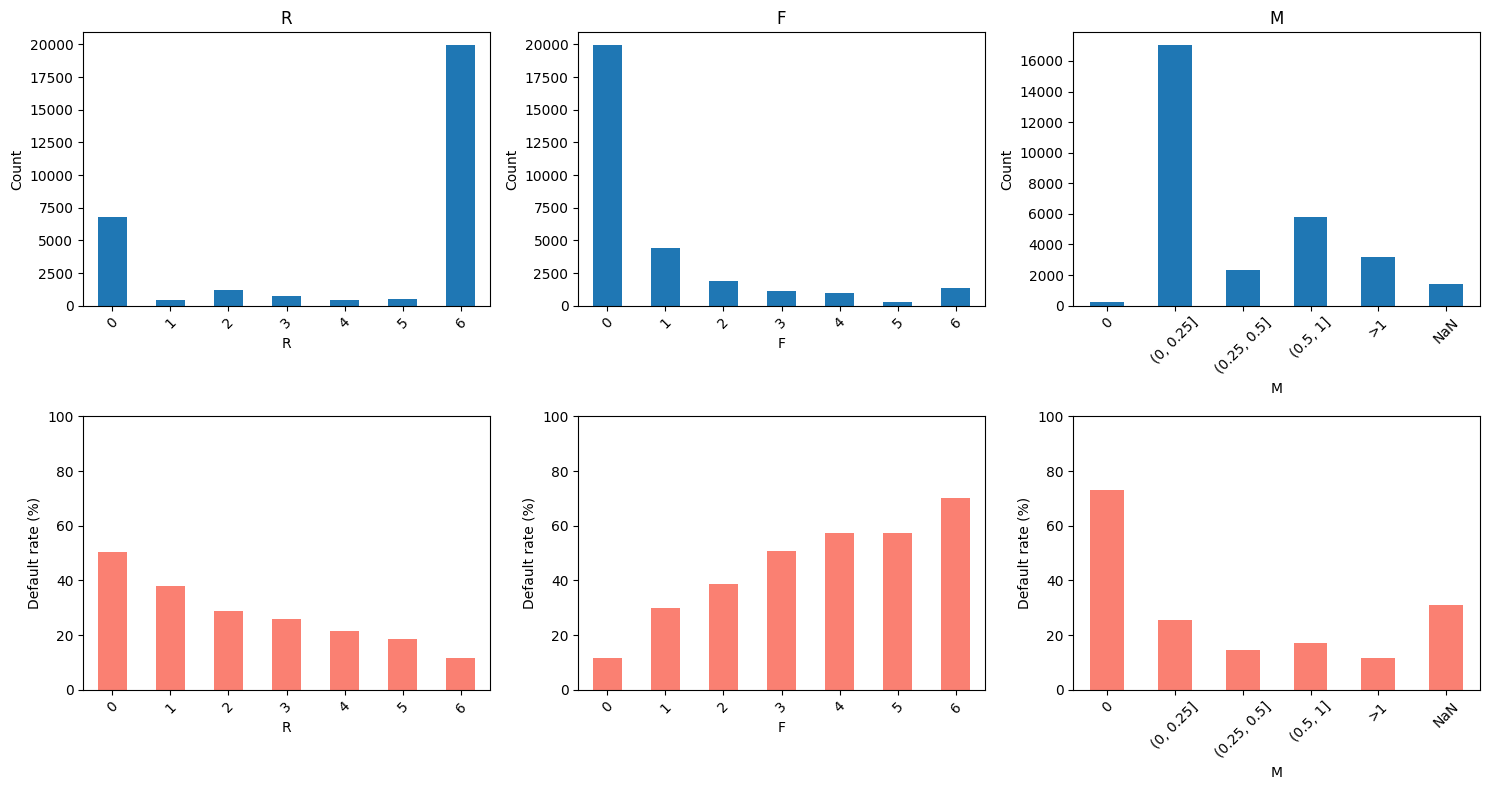

In [21]:
m_group = pd.cut(
    df_copy['m_amt_bill'], bins=[-np.inf, 0, 0.25, 0.5, 1, np.inf],
    labels=['0', '(0, 0.25]', '(0.25, 0.5]', '(0.5, 1]', '>1']
).cat.add_categories(['NaN']).fillna('NaN')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (name, group) in enumerate([
    ('R', df_copy['r_months_since_delay']),
    ('F', df_copy['f_total_delay_months']),
    ('M', m_group)
]):
    rfm_summary = df_copy.groupby(group, observed=False)[TARGET].agg(['mean', 'size'])
    rfm_summary['size'].plot.bar(ax=axes[0, i], rot=45)
    (rfm_summary['mean'] * 100).plot.bar(ax=axes[1, i], rot=45, color='salmon')
    axes[0, i].set(xlabel=name, ylabel='Count', title=name)
    axes[1, i].set(xlabel=name, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

# MODEL

**Cách chia:**
Chia dataset ra thành 3 phần 60/20/20.
+ 60% train: dùng cross-validation 3 fold để chọn mô hình và siêu tham số. Sau khi chọn xong, huấn luyện lại mô hình trên toàn bộ 60% này.
+ 20% validation: dùng để chọn ngưỡng phân loại phù hợp, chẳng hạn ưu tiên phát hiện khách hàng default nhiều hơn.
+ 20% test: dùng để đánh giá cuối cùng sau khi đã chốt mô hình, siêu tham số và ngưỡng. Không dùng kết quả test để điều chỉnh tiếp.

In [22]:
from sklearn.model_selection import train_test_split, StratifiedKFold

RFM = ["r_months_since_delay", "f_total_delay_months", "m_amt_bill"]
X = df_copy[RAW + RFM]
y = df_copy[TARGET]

In [23]:
# Chia train , val, test
X_model, X_test, y_model, y_test = train_test_split(X, y, train_size=0.8, test_size=0.2, stratify=y, random_state=SEED, shuffle=True)

X_train, X_val, y_train, y_val = train_test_split(X_model, y_model, train_size=0.75, test_size=0.25, stratify=y_model, random_state=SEED, shuffle=True)

# K FOLD
cv = StratifiedKFold(n_splits=FOLD, random_state=SEED, shuffle=True)

In [24]:
split_summary = pd.DataFrame([
    {"split": name, "rows": len(labels), "share": len(labels) / len(y),
     "default_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
])

split_summary

,split,rows,share,default_rate
0,train,18000,0.6,0.221222
1,validation,6000,0.2,0.221167
2,test,6000,0.2,0.221167


**Tiền xử lý:**
+ Biến số: điền NaN bằng median. Logistic Regression có thêm RobustScaler.
+ Biến phân loại: điền thiếu bằng mode và dùng OneHotEncoder.
+ Các bước được fit trong từng fold bằng Pipeline.

In [25]:
# SK Learn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# XGBoost
from xgboost import XGBClassifier

# Matplotlib
import matplotlib.pyplot as plt

In [26]:
CAT = ['SEX', 'EDUCATION', 'MARRIAGE'] + PAY
NUM = [col for col in X_train.columns if col not in CAT]

In [27]:
def make_pipeline(model, scale=False):
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', RobustScaler()))

    cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    preprocess = ColumnTransformer([
        ('num', Pipeline(num_steps), NUM),
        ('cat', cat_pipeline, CAT)
    ])

    return Pipeline([
        ('preprocess', preprocess),
        ('model', model)
    ])

**Model:**
+ Logistic Regression: mô hình tuyến tính dự đoán xác suất default.
+ Random Forest: kết hợp nhiều cây quyết định.
+ XGBoost: xây cây tuần tự để giảm lỗi dự đoán.
+ Mỗi model thử 4 bộ tham số trên cùng 3 fold của tập train.

In [28]:
models = {
    'LR': make_pipeline(LogisticRegression(max_iter=3000, random_state=SEED), scale=True),
    'RF': make_pipeline(RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1)),
    'XGB': make_pipeline(XGBClassifier(objective='binary:logistic', eval_metric='logloss', tree_method='hist', n_estimators=200, learning_rate=0.05, random_state=SEED, n_jobs=1))
}

params = {
    'LR': {'model__C': [0.1, 1.0], 'model__class_weight': [None, 'balanced']},
    'RF': {'model__min_samples_leaf': [1, 5], 'model__max_depth': [None, 12]},
    'XGB': {'model__max_depth': [3, 5], 'model__min_child_weight': [1, 5]}
}

**Cross validation:**
+ GridSearchCV thử từng bộ tham số bằng StratifiedKFold.
+ AP là metric chọn model. ROC-AUC dùng để đánh giá thêm.
+ Cấu hình tốt nhất của mỗi model được fit lại trên toàn bộ 60% train.
+ Không dùng tập val và test trong bước này.

In [29]:
searches = {}
results = []

for name, model in models.items():
    search = GridSearchCV(
        model, params[name], cv=cv,
        scoring={'AP': 'average_precision', 'ROC_AUC': 'roc_auc'}, refit='AP', n_jobs=2, error_score='raise'
    )
    search.fit(X_train, y_train)
    searches[name] = search

    idx = search.best_index_
    results.append({
        'model': name,
        'AP_mean': search.cv_results_['mean_test_AP'][idx],
        'AP_std': search.cv_results_['std_test_AP'][idx],
        'ROC_AUC_mean': search.cv_results_['mean_test_ROC_AUC'][idx]
    })

cv_result = pd.DataFrame(results).sort_values('AP_mean', ascending=False).reset_index(drop=True)
cv_result

,model,AP_mean,AP_std,ROC_AUC_mean
0,XGB,0.562394,0.007180,0.782934
1,RF,0.555486,0.009944,0.780532
2,LR,0.548389,0.004773,0.775488


In [30]:
best_name = cv_result.loc[0, 'model']
best_params = searches[best_name].best_params_
final_model = searches[best_name].best_estimator_

best_name, best_params

('XGB', {'model__max_depth': 3, 'model__min_child_weight': 1})

**Chọn ngưỡng:**
+ Dự đoán xác suất default trên 20% val.
+ Chọn ngưỡng có F1 cao nhất. Nếu bằng F1 thì lấy ngưỡng cao hơn.
+ Giữ nguyên model đã fit trên train, không fit thêm trên val.
+ F1 là tiêu chí thử nghiệm khi chưa xác định chi phí bỏ sót và cảnh báo nhầm.

In [31]:
val_proba = final_model.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)

# Giá trị cuối của precision và recall không có ngưỡng tương ứng
val_f1 = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(thresholds),
    where=(precision[:-1] + recall[:-1]) > 0
)

threshold_result = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision[:-1],
    'recall': recall[:-1],
    'F1': val_f1
})
threshold_result = threshold_result.sort_values(
    ['F1', 'threshold'], ascending=[False, False]
).reset_index(drop=True)

best_threshold = float(threshold_result.loc[0, 'threshold'])
threshold_result.head()

,threshold,precision,recall,F1
0,0.254141,0.506378,0.598342,0.548532
1,0.251999,0.505076,0.599849,0.548398
2,0.254068,0.506055,0.598342,0.548343
3,0.306939,0.555728,0.541070,0.548301
4,0.252592,0.505404,0.599096,0.548276


**Đánh giá:**
+ Dùng 20% test để đánh giá model và ngưỡng đã chọn.
+ So sánh ngưỡng 0.5 với ngưỡng chọn từ val, không chọn lại bằng test.
+ AP và ROC-AUC dùng xác suất. Accuracy, precision, recall và F1 dùng nhãn dự đoán.

In [32]:
test_proba = final_model.predict_proba(X_test)[:, 1]
results = []

for threshold in [0.5, best_threshold]:
    test_pred = (test_proba >= threshold).astype(int)
    results.append({
        'threshold': threshold,
        'AP': average_precision_score(y_test, test_proba),
        'ROC_AUC': roc_auc_score(y_test, test_proba),
        'accuracy': accuracy_score(y_test, test_pred),
        'precision': precision_score(y_test, test_pred, zero_division=0),
        'recall': recall_score(y_test, test_pred, zero_division=0),
        'F1': f1_score(y_test, test_pred, zero_division=0)
    })

test_result = pd.DataFrame(results)
test_result

,threshold,AP,ROC_AUC,accuracy,precision,recall,F1
0,0.500000,0.549975,0.778721,0.819167,0.668524,0.361718,0.469438
1,0.254141,0.549975,0.778721,0.781167,0.504510,0.590053,0.543939


In [33]:
test_pred = (test_proba >= best_threshold).astype(int)
report = classification_report(y_test, test_pred, output_dict=True, zero_division=0)

pd.DataFrame(report).T

,precision,recall,f1-score,support
0,0.877698,0.835438,0.856046,4673.000000
1,0.504510,0.590053,0.543939,1327.000000
accuracy,0.781167,0.781167,0.781167,0.781167
macro avg,0.691104,0.712745,0.699993,6000.000000
weighted avg,0.795161,0.781167,0.787019,6000.000000


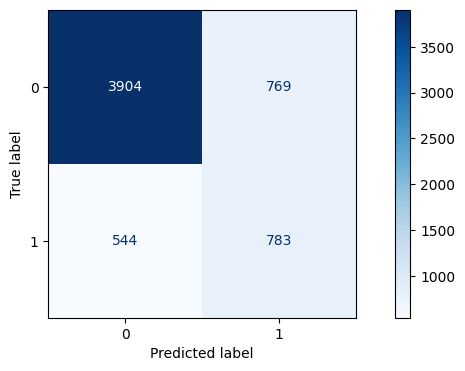

In [34]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap='Blues')
plt.show()